In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value



The shape of the feature matrix:  (98, 3)
Numerical Columns:  Index(['study_hours', 'attendance', 'previous_mark'], dtype='str')
#####################  MEAN  ##########################
study hours mean:  4.791495708334332
attendance mean:  84.38775510204081
previous mark mean:  71.04716915089323
final score mean:  42.59948445884968
####################  MEDIAN  ##################
study hours median:  4.791495708334332
attendance median:  86.0
previous mark median:  71.46543613478178
final score median:  42.55570295293528
###############  STANDARD DEVIATION  #################
study hours standard deviation:  1.7194823084661577
attendance standard deviation:  13.58867983472813
previous mark standard deviation:  16.330787490667202
final score standard deviation:  6.112900593828665


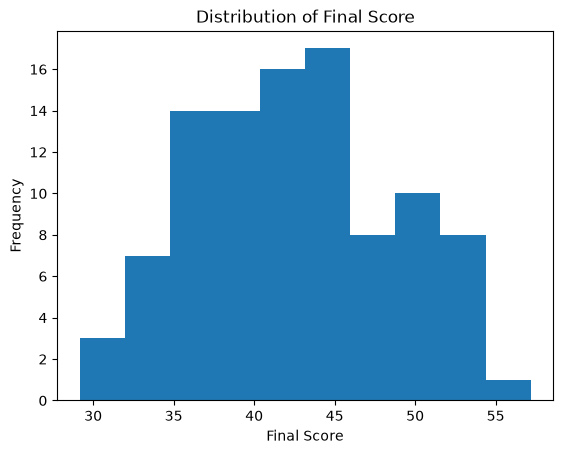

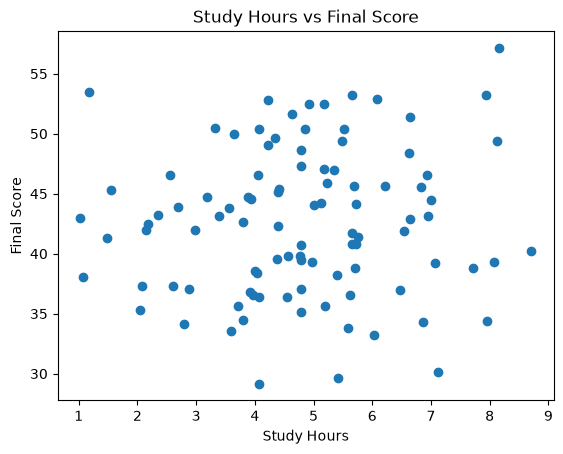

Pearson correlation coefficient: 0.07858725123496761
Predicted value:  51.74247201625687


In [21]:

# PART A Inspect and Clean

# 1. Identify the outlier in study_hours (the student with 50 hours). Remove or cap this value as you see fit. Justify your choice.

df_clean1 = df[(df["study_hours"].isna()) | ((df["study_hours"] >= 0) & (df["study_hours"] < 50))].copy() 
# The above line removes any negative study hours, and the outlier while keeping the NaN values for later imputations.

df_clean1["study_hours"] = df_clean1["study_hours"].fillna(df_clean1["study_hours"].mean()) # fill the not-available data with the mean

# Justification: 
#             I decided to impute rather than remove because the missing values are repeated (6% of the database) 
#             and by simply removing them we may lose valuable insights.



# cleaning other impossible values (attendance):
# Attendance can never be in decimal so I decided to round the values to mimick reality
# I made this decision because the decimals were merely the result of the algorith that produced the database
df_clean1["attendance"] = df_clean1["attendance"].round()

df_clean = df_clean1

# ** Another assumption is that previous marks are graded out of at least above 130



# 2. What is the shape of the feature matrix? Which columns are numerical? Which column is your target variable?

feature_matrix = df_clean.drop(columns = ["final_score"])
print ("The shape of the feature matrix: ", feature_matrix.shape) # result = (98, 3) 3 features and 98 records (98 because the cleaning removed some rows)
print("Numerical Columns: ", feature_matrix.select_dtypes(include="number").columns) # result  = Index(['study_hours', 'attendance', 'previous_mark'], dtype='str')
target= df_clean["final_score"] # The final colum is the target variable.



# Part B — Summarize

# 1. Calculate the mean, median, and standard deviation for all columns.

print ("#####################  MEAN  ##########################")

print ("study hours mean: ", df_clean["study_hours"].mean())
print ("attendance mean: ", df_clean["attendance"].mean())
print ("previous mark mean: ", df_clean["previous_mark"].mean())
print ("final score mean: ", df_clean["final_score"].mean())

print ("####################  MEDIAN  ##################")

print ("study hours median: ", df_clean["study_hours"].median())
print ("attendance median: ", df_clean["attendance"].median())
print ("previous mark median: ", df_clean["previous_mark"].median())
print ("final score median: ", df_clean["final_score"].median())

print ("###############  STANDARD DEVIATION  #################")

print ("study hours standard deviation: ", df_clean["study_hours"].std())
print ("attendance standard deviation: ", df_clean["attendance"].std())
print ("previous mark standard deviation: ", df_clean["previous_mark"].std())
print ("final score standard deviation: ", df_clean["final_score"].std())

# 2. Write 3 observations in plain English.

# Observation 1, The standard deviation of hours studied is very low, suggesting that many students have similar study hours.
# Observation 2, The mean of final scores is lower than 50 (at least at this instance of the database) suggesting low performace of students.
# Observation 3, The median of the previous mark is high (around 70) suggesting that many studnets had a high marks previously.



# PART C — Visualize

# 1. Create a histogram for final_score.

plt.hist(df_clean["final_score"], bins=10)
plt.xlabel("Final Score")
plt.ylabel("Frequency")
plt.title("Distribution of Final Score")
plt.show()

# 2. Create a scatter plot of study_hours vs final_score. Describe the trend.

plt.scatter(df_clean["study_hours"], df_clean["final_score"])

plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.title("Study Hours vs Final Score")

plt.show()

# The trend shows that students with similar study hours tend to quite achieve different final scores.

# PART D — Correlation and Causality

# 1. Calculate the Pearson correlation coefficient between study_hours and final_score.

correlation = df_clean["study_hours"].corr(df_clean["final_score"])

print("Pearson correlation coefficient:", correlation)

# 2. Critical Thinking: If a student studies 10 hours, does the correlation 

# guarantee they will get a specific score? What is a potential "lurking" or
# "confounding" variable that could explain the link between study time and scores?

# Answer: No. The Pearson correlation coefficient of 0.07 indicates a very weak positive linear relationship between study hours and final scores.
#  A potential confounding variable is previous academic performance, because students with higher previous marks may have a stronger understanding of the subject and achieve higher final scores regardless of their study hours.

# PART E — Vectors and Dot Product

# 1. Select one student row (excluding the target) as a vector \mathbf{x}.

x = feature_matrix.iloc[0].to_numpy()

# 2. Define a weight vector f{w} = [0.5, 0.2, 0.4] and a bias b = 5.

w = np.array([0.5, 0.2, 0.4])
b = 5

# 3. Calculate {y} = f{w} dot f{x} + b using NumPy.

y = np.dot(w, x) + b
print ("Predicted value: ", y)

# 4. Conceptually: What does f{w} represent in the context of predicting a score? Why do we need b?

#Answer:  Weights represent each feature's contribution to the prediction.
#         The bias adds a constant to the prediction, allowing the model
#         to predict a nonzero score when all features are zero.

# PART F — Scaling

# 1. Standardize study_hours and previous_mark (use (x -mean) / standard degviation).

# Standardize study_hours_scaled
df_clean["study_hours_scaled"] = (
    df_clean["study_hours"] - df_clean["study_hours"].mean()
) / df_clean["study_hours"].std()

# Standardize previous_mark
df_clean["previous_mark_scaled"] = (
    df_clean["previous_mark"] - df_clean["previous_mark"].mean()
) / df_clean["previous_mark"].std()

# 2. Why would a distance-based algorithm (like K-Nearest Neighbors) fail if we 
#    didn't scale these two features? (Hint: compare the original range of
#    study_hours vs previous_mark).

# Answer: Standardization puts study_hours and previous_mark on comparable scales. 
#         Without it, KNN's distance calculations could be dominated by previous_mark, whose numerical values vary over a larger range than study hours. 
#         Scaling helps both features contribute more fairly to distance calculations.